In [1]:
# Import Libraries
import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv(
    r'C:\Users\sunda\OneDrive\Desktop\Python_works\job_postings_flat.csv'
)

In [2]:
# find the top 6 skills trend
# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df['job_skills'] = df['job_skills'].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else []
)

# Create Month Number and Month Name
df['job_posted_month_no'] = df['job_posted_date'].dt.month
df['job_posted_month'] = df['job_posted_date'].dt.strftime('%b')

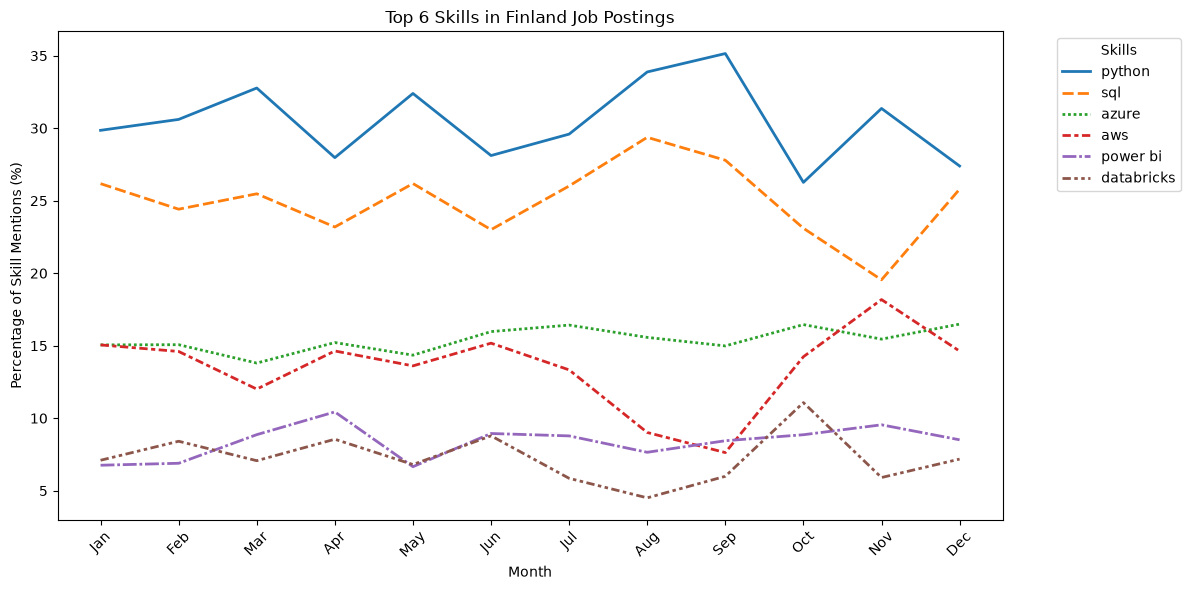

In [3]:
# Filter Finland jobs
df_fin = df[df['job_country'] == 'Finland'].copy()

# Explode skills list
df_fin_explode = df_fin.explode('job_skills')

# Create pivot table
df_fin_pivot = (
    df_fin_explode
    .pivot_table(
        index=['job_posted_month_no', 'job_posted_month'],
        columns='job_skills',
        aggfunc='size',
        fill_value=0
    )
    .sort_index(level=0)
)

# Convert MultiIndex to Month Name index
df_fin_pivot = df_fin_pivot.reset_index()
df_fin_pivot = df_fin_pivot.set_index('job_posted_month')
df_fin_pivot = df_fin_pivot.drop(columns='job_posted_month_no')

# Find Top 5 Skills Overall
top_skills = (
    df_fin_pivot
    .sum()
    .sort_values(ascending=False)
    .head(6)
    .index
)

# Keep only Top 6 Skills
df_plot = df_fin_pivot[top_skills]

# Convert Monthly Counts to Percentages
df_plot_pct = (
    df_plot
    .div(df_plot.sum(axis=1), axis=0)
    * 100
)

# Plot
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_plot_pct,
    linewidth=2
)

plt.title('Top 6 Skills in Finland Job Postings')
plt.xlabel('Month')
plt.ylabel('Percentage of Skill Mentions (%)')

plt.xticks(rotation=45)

plt.legend(
    title='Skills',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

In [4]:
df_plot_pct.to_csv("skill_trends.csv")